# Re-project Hippo time-course onto perturb-seq cNMF programs using different gene sets

Purpose:
- Test whether broad P35 assignment is caused by using too broad a gene set during projection.
- Compare projections using:
  1. all shared reference genes;
  2. original cNMF overdispersed/HVG genes;
  3. union of top loading genes per program;
  4. union of program-specific genes per program.

Main outputs:
- a compact AnnData with cell × program usages for each projection mode;
- P35 broadness/marker-correlation diagnostics;
- key program treatment effect comparisons across projection modes;
- Illustrator-editable SVG plots.

In [1]:
from __future__ import annotations

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import scanpy as sc
from scipy import sparse, stats
import matplotlib as mpl
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 7,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

try:
    from sklearn.decomposition import non_negative_factorization
except Exception as e:
    raise ImportError(
        "This notebook requires scikit-learn. Install with: pip install scikit-learn"
    ) from e

try:
    display
except NameError:
    def display(x):
        print(x if not hasattr(x, "head") else x.head(30).to_string())

## Settings

In [2]:
BASE = Path("/scratch/users/edtng/20260325_Hippo_timecourse")

# Use the original combined h5ad, or the projected h5ad if that is the one that still contains RNA X.
QUERY_H5AD = BASE / "perturbseq_cNMF_projection" / "Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad"
# Alternative:
# QUERY_H5AD = BASE / "Hippo_timecourse_combined.h5ad"

CNMF_ROOT = Path(
    "/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/"
    "030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50"
)

SPECTRA_TPM = CNMF_ROOT / (
    "030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50."
    "gene_spectra_tpm.k_50.dt_0_2.txt"
)

OVERDISPERSED_GENES = CNMF_ROOT / (
    "030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50."
    "overdispersed_genes.txt"
)

CNMF_XLSX = BASE / "cNMF_50_0_2_032526_6co.xlsx"
if not CNMF_XLSX.exists() and Path("/mnt/data/cNMF_50_0_2_032526_6co.xlsx").exists():
    CNMF_XLSX = Path("/mnt/data/cNMF_50_0_2_032526_6co.xlsx")

OUT_DIR = BASE / "perturbseq_cNMF_projection" / "reprojection_gene_set_comparison"
FIG_DIR = OUT_DIR / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Query gene IDs. Your time-course adata.var usually has a gene symbol column called "gene".
QUERY_GENE_ID_SOURCE = "column"   # "var_names" or "column"
QUERY_GENE_COLUMN = "gene"

# Counts source in query adata.
# Use "X" if adata.X is raw counts. Use "layer:mature" / "layer:nascent" if desired.
COUNTS_SOURCE = "X"
TARGET_SUM = 1e6

# Projection settings.
SKLEARN_MAX_ITER = 1000
SKLEARN_TOL = 1e-5
RANDOM_STATE = 0

# Gene-set projection modes.
TOP_LOADING_N = 300
TOP_SPECIFIC_N = 200
MIN_QUERY_DETECTED_CELLS = 20

# CLR settings.
CLR_EPS = 1e-6
LOG_BASE = 2

# Programs to diagnose.
PROGRAM_OF_INTEREST = "P35"
KEY_PROGRAMS = ["P15", "P17", "P34", "P35"]

# Treatment contrasts for effect diagnostics.
CONTRASTS = [
    {"name": "D2_TDI", "treatment": "TDI", "treated_condition": "D2_LM+TDI", "control_condition": "D2_LM"},
    {"name": "D2_IAG", "treatment": "IAG", "treated_condition": "D2_LM+IAG", "control_condition": "D2_LM"},
    {"name": "D3_TDI", "treatment": "TDI", "treated_condition": "D3_AE+TDI", "control_condition": "D3_AE"},
    {"name": "D3_IAG", "treatment": "IAG", "treated_condition": "D3_AE+IAG", "control_condition": "D3_AE"},
    {"name": "D2toD3_TDI", "treatment": "TDI", "treated_condition": "D2_LM+TDI->D3_AE+TDI", "control_condition": "D3_AE"},
    {"name": "D2toD3_IAG", "treatment": "IAG", "treated_condition": "D2_LM+IAG->D3_AE+IAG", "control_condition": "D3_AE"},
]

# QC cutoffs from your time-course filtering.
COND_PCT_RIBO_CUTOFFS = {
    'D0_hPSC': 2.4,
    'D1_MPS': 2.3,
    'D1_MPS+TDI': 2.5,
    'D1_MPS+IAG': 2.2,
    'D1.33_LM': 1.9,
    'D1.33_LM+TDI': 2.1,
    'D1.33_LM+IAG': 2.2,
    'D1.67_LM': 2.0,
    'D1.67_LM+TDI': 2.2,
    'D1.67_LM+IAG': 1.9,
    'D2_LM': 2.0,
    'D2_LM+TDI': 2.4,
    'D2_LM+IAG': 1.9,
    'D3_AE': 1.0,
    'D3_AE+TDI': 2.0,
    'D3_AE+IAG': 1.0,
    'D2_LM+TDI->D3_AE+TDI': 2.5,
    'D2_LM+IAG->D3_AE+IAG': 1.0,
}

COND_PCT_MT_CUTOFFS = {
    'D0_hPSC': 5.5,
    'D1_MPS': 3.0,
    'D1_MPS+TDI': 3.0,
    'D1_MPS+IAG': 4,
    'D1.33_LM': 3.5,
    'D1.33_LM+TDI': 3.75,
    'D1.33_LM+IAG': 5,
    'D1.67_LM': 4.0,
    'D1.67_LM+TDI': 5.5,
    'D1.67_LM+IAG': 3.5,
    'D2_LM': 6.5,
    'D2_LM+TDI': 8,
    'D2_LM+IAG': 3.5,
    'D3_AE': 3.25,
    'D3_AE+TDI': 7.0,
    'D3_AE+IAG': 3.75,
    'D2_LM+TDI->D3_AE+TDI': 7,
    'D2_LM+IAG->D3_AE+IAG': 3.75,
}

print("QUERY_H5AD:", QUERY_H5AD, QUERY_H5AD.exists())
print("SPECTRA_TPM:", SPECTRA_TPM, SPECTRA_TPM.exists())
print("OVERDISPERSED_GENES:", OVERDISPERSED_GENES, OVERDISPERSED_GENES.exists())
print("CNMF_XLSX:", CNMF_XLSX, CNMF_XLSX.exists())
print("OUT_DIR:", OUT_DIR)

QUERY_H5AD: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad True
SPECTRA_TPM: /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50.gene_spectra_tpm.k_50.dt_0_2.txt True
OVERDISPERSED_GENES: /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50.overdispersed_genes.txt True
CNMF_XLSX: /scratch/users/edtng/20260325_Hippo_timecourse/cNMF_50_0_2_032526_6co.xlsx True
OUT_DIR: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/reprojection_gene_set_comparison


## Helper functions

In [3]:
def program_num(program: str) -> int:
    m = re.fullmatch(r"P(\d+)", str(program))
    if m is None:
        raise ValueError(f"Invalid program name: {program!r}")
    return int(m.group(1))


def parse_sample_name(sample_name: str):
    m = re.match(r"^(.*)_rep(\d+)$", str(sample_name))
    if m is None:
        return str(sample_name), np.nan
    return m.group(1), int(m.group(2))


def derive_treatment(condition: str) -> str:
    condition = str(condition)
    if "TDI" in condition:
        return "TDI"
    if "IAG" in condition:
        return "IAG"
    return "control"


def bh_adjust(pvalues):
    pvalues = np.asarray(pvalues, dtype=float)
    out = np.full_like(pvalues, np.nan, dtype=float)
    valid = np.isfinite(pvalues)
    p = pvalues[valid]
    if len(p) == 0:
        return out
    order = np.argsort(p)
    ranked = p[order]
    n = len(ranked)
    adj = ranked * n / np.arange(1, n + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    adj = np.clip(adj, 0, 1)
    tmp = np.empty_like(adj)
    tmp[order] = adj
    out[valid] = tmp
    return out


def clr_transform_usage(usage, eps=1e-6, log_base=2):
    usage = np.asarray(usage, dtype=np.float64)
    row_sums = usage.sum(axis=1, keepdims=True)
    if np.any(row_sums <= 0):
        raise ValueError("Some cells have zero total usage.")
    usage = usage / row_sums
    usage = np.maximum(usage, eps)
    usage = usage / usage.sum(axis=1, keepdims=True)
    if log_base == 2:
        log_usage = np.log2(usage)
    elif log_base == "natural":
        log_usage = np.log(usage)
    else:
        raise ValueError("log_base must be 2 or 'natural'.")
    return (log_usage - log_usage.mean(axis=1, keepdims=True)).astype(np.float32)


def zscore_rows(df):
    z = df.sub(df.mean(axis=1), axis=0)
    z = z.div(df.std(axis=1).replace(0, np.nan), axis=0)
    return z.fillna(0)


def plot_heatmap(df, title, out_prefix, cmap="RdBu_r", center_zero=True):
    mat = df.to_numpy(dtype=float)
    n_rows, n_cols = mat.shape
    if center_zero:
        vmax = np.nanmax(np.abs(mat))
        if not np.isfinite(vmax) or vmax == 0:
            vmax = 1
        vmin = -vmax
    else:
        vmin, vmax = np.nanmin(mat), np.nanmax(mat)
        if not np.isfinite(vmin) or not np.isfinite(vmax) or vmin == vmax:
            vmin, vmax = 0, 1

    fig_w = max(6, 0.45 * n_cols + 3)
    fig_h = max(4, 0.30 * n_rows + 2)
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    im = ax.pcolormesh(
        np.arange(n_cols + 1),
        np.arange(n_rows + 1),
        mat,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        shading="flat",
        linewidth=0.25,
        edgecolors="white",
    )
    ax.set_xlim(0, n_cols)
    ax.set_ylim(n_rows, 0)
    ax.set_xticks(np.arange(n_cols) + 0.5)
    ax.set_yticks(np.arange(n_rows) + 0.5)
    ax.set_xticklabels(df.columns.tolist(), rotation=45, ha="right")
    ax.set_yticklabels(df.index.tolist())
    ax.set_title(title)
    ax.tick_params(length=0)
    cb = fig.colorbar(im, ax=ax, pad=0.02)
    cb.ax.tick_params(labelsize=7)
    fig.tight_layout()
    for ext in ["svg", "pdf", "png"]:
        fig.savefig(FIG_DIR / f"{out_prefix}.{ext}", bbox_inches="tight")
    plt.show()
    plt.close(fig)


def read_spectra(path):
    W = pd.read_csv(path, sep="\t", index_col=0)
    W.index = W.index.astype(str)
    W.columns = W.columns.astype(str)
    # cNMF exported rows are often 1..50; convert to zero-based P0..P49.
    try:
        ids = [int(float(x)) for x in W.index]
        if ids == list(range(1, W.shape[0] + 1)):
            W.index = [f"P{i}" for i in range(W.shape[0])]
        elif ids == list(range(W.shape[0])):
            W.index = [f"P{i}" for i in ids]
        else:
            W.index = [f"P{i}" for i in ids]
    except Exception:
        pass
    W = W.apply(pd.to_numeric, errors="coerce").fillna(0.0)
    W[W < 0] = 0.0
    W = W.loc[[f"P{i}" for i in range(W.shape[0])]]
    return W


def get_query_gene_ids(adata):
    if QUERY_GENE_ID_SOURCE == "var_names":
        genes = pd.Index(adata.var_names.astype(str))
    elif QUERY_GENE_ID_SOURCE == "column":
        if QUERY_GENE_COLUMN not in adata.var.columns:
            raise KeyError(f"{QUERY_GENE_COLUMN!r} not found in adata.var")
        genes = pd.Index(adata.var[QUERY_GENE_COLUMN].astype(str).to_numpy())
    else:
        raise ValueError("QUERY_GENE_ID_SOURCE must be 'var_names' or 'column'.")
    return genes


def get_counts_matrix(adata):
    if COUNTS_SOURCE == "X":
        X = adata.X
    elif COUNTS_SOURCE.startswith("layer:"):
        layer = COUNTS_SOURCE.split(":", 1)[1]
        if layer not in adata.layers:
            raise KeyError(f"Layer {layer!r} not found in adata.layers")
        X = adata.layers[layer]
    else:
        raise ValueError("COUNTS_SOURCE must be X or layer:<name>")
    if sparse.issparse(X):
        return X.tocsr()
    return sparse.csr_matrix(X)


def build_collapsed_query_matrix(X_counts, query_gene_ids, selected_ref_genes, total_counts):
    """Return CPM sparse matrix with columns exactly selected_ref_genes order."""
    selected_ref_genes = pd.Index([str(g) for g in selected_ref_genes])
    # Map query gene id -> query column positions. Duplicates are summed.
    gene_to_positions = {}
    for i, g in enumerate(query_gene_ids.astype(str)):
        if g in selected_ref_genes:
            gene_to_positions.setdefault(g, []).append(i)

    missing = [g for g in selected_ref_genes if g not in gene_to_positions]
    present = [g for g in selected_ref_genes if g in gene_to_positions]
    if missing:
        print(f"  Warning: {len(missing)} selected reference genes missing from query. Examples: {missing[:10]}")

    query_positions = []
    target_positions = []
    present_index = {g: j for j, g in enumerate(present)}
    for g in present:
        j = present_index[g]
        for pos in gene_to_positions[g]:
            query_positions.append(pos)
            target_positions.append(j)

    X_sub = X_counts[:, query_positions].tocsr()
    C = sparse.csr_matrix(
        (np.ones(len(query_positions), dtype=np.float32), (np.arange(len(query_positions)), target_positions)),
        shape=(len(query_positions), len(present)),
    )
    X_collapsed = X_sub @ C

    scale = np.divide(
        TARGET_SUM,
        total_counts,
        out=np.zeros_like(total_counts, dtype=np.float64),
        where=total_counts > 0,
    )
    X_cpm = X_collapsed.multiply(scale[:, None]).tocsr().astype(np.float32)
    return X_cpm, present


def project_fixed_spectra(X_cpm, H_program_by_gene, mode_name):
    """Project cells x genes onto fixed programs x genes H using sklearn fixed-H NMF.

    scikit-learn requires X and H to have the same dtype. The query matrix is
    usually float32 after CPM normalization, while pandas/numpy reads spectra as
    float64 by default. Cast both to float32 here.
    """
    target_dtype = np.float32

    if sparse.issparse(X_cpm):
        X_input = X_cpm.astype(target_dtype)
    else:
        X_input = np.asarray(X_cpm, dtype=target_dtype, order="C")

    H = np.asarray(H_program_by_gene, dtype=target_dtype, order="C")
    H[H < 0] = 0.0

    # Normalize H rows to comparable scale.
    H_row_sums = H.sum(axis=1, keepdims=True)
    H = np.divide(
        H,
        np.maximum(H_row_sums, np.asarray(1e-12, dtype=target_dtype)),
        out=np.zeros_like(H, dtype=target_dtype),
        where=H_row_sums > 0,
    ).astype(target_dtype, copy=False)

    print(
        f"  Projecting {mode_name}: "
        f"X={X_input.shape} dtype={X_input.dtype}, "
        f"H={H.shape} dtype={H.dtype}"
    )

    W_usage, _, n_iter = non_negative_factorization(
        X_input,
        H=H,
        n_components=H.shape[0],
        update_H=False,
        init="custom",
        solver="mu",
        beta_loss="frobenius",
        max_iter=SKLEARN_MAX_ITER,
        tol=SKLEARN_TOL,
        random_state=RANDOM_STATE,
        verbose=0,
    )

    W_usage = np.asarray(W_usage, dtype=target_dtype)
    row_sums = W_usage.sum(axis=1, keepdims=True)

    W_norm = np.divide(
        W_usage,
        row_sums,
        out=np.zeros_like(W_usage),
        where=row_sums > 0,
    )

    print(
        f"  Done {mode_name}: n_iter={n_iter}; "
        f"row sum range raw={row_sums.min():.4g}..{row_sums.max():.4g}"
    )

    return W_usage.astype(np.float32), W_norm.astype(np.float32), int(n_iter)


def paired_clr_effects(sample_clr_mean, sample_meta, program_names, mode_name):
    records = []
    for contrast in CONTRASTS:
        tcond = contrast["treated_condition"]
        ccond = contrast["control_condition"]
        treated = sample_meta[sample_meta["condition"] == tcond]
        control = sample_meta[sample_meta["condition"] == ccond]
        t_by_rep = {int(r["replicate"]): s for s, r in treated.iterrows()}
        c_by_rep = {int(r["replicate"]): s for s, r in control.iterrows()}
        reps = sorted(set(t_by_rep) & set(c_by_rep))
        for p in program_names:
            cvals, tvals, diffs = [], [], []
            for rep in reps:
                c = float(sample_clr_mean.loc[c_by_rep[rep], p])
                t = float(sample_clr_mean.loc[t_by_rep[rep], p])
                cvals.append(c); tvals.append(t); diffs.append(t-c)
            cvals, tvals, diffs = map(lambda x: np.asarray(x, dtype=float), [cvals, tvals, diffs])
            if len(diffs) >= 2 and np.std(diffs, ddof=1) > 0:
                stat, pval = stats.ttest_rel(tvals, cvals, nan_policy="omit")
            else:
                stat, pval = np.nan, np.nan
            records.append({
                "projection_mode": mode_name,
                "contrast_name": contrast["name"],
                "treatment": contrast["treatment"],
                "treated_condition": tcond,
                "control_condition": ccond,
                "program": p,
                "n_matched_pairs": len(reps),
                "mean_control_clr": float(np.nanmean(cvals)) if len(cvals) else np.nan,
                "mean_treated_clr": float(np.nanmean(tvals)) if len(tvals) else np.nan,
                "mean_diff_clr": float(np.nanmean(diffs)) if len(diffs) else np.nan,
                "sd_diff_clr": float(np.nanstd(diffs, ddof=1)) if len(diffs) > 1 else np.nan,
                "t_statistic": float(stat) if np.isfinite(stat) else np.nan,
                "pvalue": float(pval) if np.isfinite(pval) else np.nan,
                "n_positive_diffs": int((diffs > 0).sum()) if len(diffs) else 0,
                "n_negative_diffs": int((diffs < 0).sum()) if len(diffs) else 0,
            })
    out = pd.DataFrame(records)
    out["padj_bh_within_mode_contrast"] = np.nan
    for _, idx in out.groupby(["projection_mode", "contrast_name"]).groups.items():
        out.loc[idx, "padj_bh_within_mode_contrast"] = bh_adjust(out.loc[idx, "pvalue"].to_numpy())
    return out

## Load query data and reference spectra

In [4]:
print("Loading query AnnData:", QUERY_H5AD)
adata = sc.read_h5ad(QUERY_H5AD)
print(adata)

# Parse sample metadata.
if "sample_name" not in adata.obs.columns:
    raise KeyError("sample_name missing from adata.obs")
parsed = adata.obs["sample_name"].astype(str).map(parse_sample_name)
adata.obs["condition"] = [x[0] for x in parsed]
adata.obs["replicate"] = [x[1] for x in parsed]
adata.obs["treatment"] = adata.obs["condition"].map(derive_treatment)

# QC pass flag.
for col in ["pct_counts_mt", "pct_counts_ribo"]:
    if col not in adata.obs.columns:
        raise KeyError(f"{col} missing from adata.obs")
    adata.obs[col] = pd.to_numeric(adata.obs[col], errors="coerce")

qc_pass = np.ones(adata.n_obs, dtype=bool)
for cond in adata.obs["condition"].astype(str).unique():
    if cond not in COND_PCT_MT_CUTOFFS or cond not in COND_PCT_RIBO_CUTOFFS:
        print("Warning: missing cutoff for", cond, "keeping cells without condition-specific filter")
        continue
    m = adata.obs["condition"].astype(str).to_numpy() == cond
    fail = m & (
        (adata.obs["pct_counts_mt"].to_numpy() >= COND_PCT_MT_CUTOFFS[cond]) |
        (adata.obs["pct_counts_ribo"].to_numpy() <= COND_PCT_RIBO_CUTOFFS[cond])
    )
    qc_pass &= ~fail
adata.obs["qc_pass_condition_specific"] = qc_pass
print("QC pass:", qc_pass.sum(), "/", len(qc_pass))

# Load counts and query gene IDs.
X_counts = get_counts_matrix(adata)
query_gene_ids = get_query_gene_ids(adata)
print("X_counts:", X_counts.shape, "nnz", X_counts.nnz)
print("query_gene_ids examples:", query_gene_ids[:5].tolist())

# Total counts for full-library CPM normalization.
if "total_counts" in adata.obs.columns:
    total_counts = pd.to_numeric(adata.obs["total_counts"], errors="coerce").to_numpy(dtype=float)
else:
    total_counts = np.asarray(X_counts.sum(axis=1)).ravel().astype(float)
print("total_counts range:", np.nanmin(total_counts), np.nanmax(total_counts))

# Reference spectra.
W_ref = read_spectra(SPECTRA_TPM)
program_names = W_ref.index.tolist()
print("W_ref:", W_ref.shape)
print("programs:", program_names[:5], "...", program_names[-5:])

Loading query AnnData: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad


AnnData object with n_obs × n_vars = 212891 × 62757
    obs: 'guides_per_cell', 'guide_umi_counts', 'pct_counts_ribo', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'pool', 'sample_id', 'round1', 'well', 'biological_sample', 'plate', 'sublibID', 'sample_name', 'perturbseq_cNMF_P0_usage', 'perturbseq_cNMF_P1_usage', 'perturbseq_cNMF_P2_usage', 'perturbseq_cNMF_P3_usage', 'perturbseq_cNMF_P4_usage', 'perturbseq_cNMF_P5_usage', 'perturbseq_cNMF_P6_usage', 'perturbseq_cNMF_P7_usage', 'perturbseq_cNMF_P8_usage', 'perturbseq_cNMF_P9_usage', 'perturbseq_cNMF_P10_usage', 'perturbseq_cNMF_P11_usage', 'perturbseq_cNMF_P12_usage', 'perturbseq_cNMF_P13_usage', 'perturbseq_cNMF_P14_usage', 'perturbseq_cNMF_P15_usage', 'perturbseq_cNMF_P16_usage', 'perturbseq_cNMF_P17_usage', 'perturbseq_cNMF_P18_usage', 'perturbseq_cNMF_P19_usage', 'perturbseq_cNMF_P20_usage', 'perturbseq_cNMF_P21_usage', 'perturbseq_cNMF_P22_usage', 'perturbseq_cNMF_P23_usage', 'perturbseq_cNMF_P24_usage

## Build gene set options

In [5]:
ref_genes = pd.Index(W_ref.columns.astype(str))
query_genes_set = set(query_gene_ids.astype(str))

# 1. all shared genes
all_shared_genes = [g for g in ref_genes if g in query_genes_set]

# 2. original overdispersed/HVG genes
if OVERDISPERSED_GENES.exists():
    hvg = pd.read_csv(OVERDISPERSED_GENES, header=None)[0].astype(str).tolist()
    hvg_shared_genes = [g for g in hvg if g in set(ref_genes) and g in query_genes_set]
else:
    print("OVERDISPERSED_GENES not found; hvg_shared will be skipped.")
    hvg_shared_genes = []

# 3. union of top loading genes per program
loading_genes = []
for p in W_ref.index:
    loading_genes.extend(W_ref.loc[p].sort_values(ascending=False).head(TOP_LOADING_N).index.astype(str).tolist())
top_loading_union_genes = [g for g in pd.Index(loading_genes).drop_duplicates() if g in query_genes_set]

# 4. union of top program-specific genes per program
# Specificity is fraction of a gene's total spectra weight assigned to the program.
gene_total = W_ref.sum(axis=0).replace(0, np.nan)
specificity = W_ref.div(gene_total, axis=1).fillna(0)
specific_genes = []
for p in W_ref.index:
    tmp = pd.DataFrame({
        "gene": W_ref.columns.astype(str),
        "specificity": specificity.loc[p].to_numpy(),
        "weight": W_ref.loc[p].to_numpy(),
    }).sort_values(["specificity", "weight"], ascending=False)
    specific_genes.extend(tmp.head(TOP_SPECIFIC_N)["gene"].tolist())
top_specific_union_genes = [g for g in pd.Index(specific_genes).drop_duplicates() if g in query_genes_set]

GENE_SETS = {
    "all_shared": all_shared_genes,
    "hvg_overdispersed": hvg_shared_genes,
    f"top_loading_{TOP_LOADING_N}": top_loading_union_genes,
    f"top_specific_{TOP_SPECIFIC_N}": top_specific_union_genes,
}
GENE_SETS = {k: v for k, v in GENE_SETS.items() if len(v) > 0}

gene_set_summary = pd.DataFrame({
    "projection_mode": list(GENE_SETS.keys()),
    "n_genes": [len(v) for v in GENE_SETS.values()],
})
gene_set_summary.to_csv(OUT_DIR / "projection_gene_set_summary.tsv", sep="\t", index=False)
display(gene_set_summary)

# Save gene lists.
for mode, genes in GENE_SETS.items():
    pd.Series(genes, name="gene").to_csv(OUT_DIR / f"genes_used_{mode}.txt", index=False, header=False)

# P35-specific genes for marker expression diagnostics.
P35_specific_genes = (
    pd.DataFrame({
        "gene": W_ref.columns.astype(str),
        "P35_weight": W_ref.loc[PROGRAM_OF_INTEREST].to_numpy(),
        "P35_specificity": specificity.loc[PROGRAM_OF_INTEREST].to_numpy(),
    })
    .sort_values(["P35_specificity", "P35_weight"], ascending=False)
)
P35_MARKERS = [g for g in P35_specific_genes.head(25)["gene"].tolist() if g in query_genes_set]
P35_specific_genes.to_csv(OUT_DIR / f"{PROGRAM_OF_INTEREST}_specific_genes_from_spectra.tsv", sep="\t", index=False)
print("P35 markers for diagnostic expression:", P35_MARKERS[:10], "n=", len(P35_MARKERS))

,projection_mode,n_genes
0,all_shared,17480
1,hvg_overdispersed,17480
2,top_loading_300,3297
3,top_specific_200,7268


P35 markers for diagnostic expression: ['AREG', 'ENSG00000222032', 'COL12A1', 'LTBP2', 'PTPRN', 'LOX', 'PLAT', 'TM4SF1', 'XIRP1', 'TRAF1'] n= 25


## Run projections for each gene set

In [6]:
projection_usages = {}
projection_usages_raw = {}
projection_clr = {}
projection_stats = []

for mode, genes in GENE_SETS.items():
    print("\n=== Projection mode:", mode, "===")
    genes = [g for g in genes if g in W_ref.columns]
    X_cpm, present_genes = build_collapsed_query_matrix(X_counts, query_gene_ids, genes, total_counts)
    H = W_ref.loc[program_names, present_genes].to_numpy()
    W_raw, W_norm, n_iter = project_fixed_spectra(X_cpm, H, mode)
    W_clr = clr_transform_usage(W_norm, eps=CLR_EPS, log_base=LOG_BASE)
    projection_usages_raw[mode] = W_raw
    projection_usages[mode] = W_norm
    projection_clr[mode] = W_clr
    projection_stats.append({"projection_mode": mode, "n_genes": len(present_genes), "n_iter": n_iter})

projection_stats_df = pd.DataFrame(projection_stats)
projection_stats_df.to_csv(OUT_DIR / "projection_runtime_summary.tsv", sep="\t", index=False)
display(projection_stats_df)


=== Projection mode: all_shared ===


  Projecting all_shared: X=(212891, 17480) dtype=float32, H=(50, 17480) dtype=float32
  Done all_shared: n_iter=920; row sum range raw=8.322e+04..1.477e+06

=== Projection mode: hvg_overdispersed ===
  Projecting hvg_overdispersed: X=(212891, 17480) dtype=float32, H=(50, 17480) dtype=float32
  Done hvg_overdispersed: n_iter=920; row sum range raw=8.322e+04..1.477e+06

=== Projection mode: top_loading_300 ===
  Projecting top_loading_300: X=(212891, 3297) dtype=float32, H=(50, 3297) dtype=float32
  Done top_loading_300: n_iter=1000; row sum range raw=6.086e+04..1.19e+06

=== Projection mode: top_specific_200 ===
  Projecting top_specific_200: X=(212891, 7268) dtype=float32, H=(50, 7268) dtype=float32
  Done top_specific_200: n_iter=140; row sum range raw=9.046e+04..5.161e+05


,projection_mode,n_genes,n_iter
0,all_shared,17480,920
1,hvg_overdispersed,17480,920
2,top_loading_300,3297,1000
3,top_specific_200,7268,140


## Save compact AnnData with all projection modes

In [7]:
obs_out = adata.obs.copy()
var_out = pd.DataFrame(index=pd.Index(program_names, name="program"))
var_out["program"] = program_names
var_out["program_id_zero_based"] = [program_num(p) for p in program_names]

# Put one projection into X for convenience; all are in obsm/layers-like obsm keys.
first_mode = list(projection_usages.keys())[0]
adata_proj = sc.AnnData(
    X=projection_usages[first_mode].astype(np.float32),
    obs=obs_out,
    var=var_out,
)
adata_proj.uns["projection_modes"] = list(projection_usages.keys())
adata_proj.uns["reference_spectra"] = str(SPECTRA_TPM)
adata_proj.uns["query_h5ad"] = str(QUERY_H5AD)

for mode in projection_usages:
    adata_proj.obsm[f"X_cnmf_usage_{mode}"] = projection_usages[mode].astype(np.float32)
    adata_proj.obsm[f"X_cnmf_usage_raw_{mode}"] = projection_usages_raw[mode].astype(np.float32)
    adata_proj.obsm[f"X_cnmf_clr_{mode}"] = projection_clr[mode].astype(np.float32)

out_h5ad = OUT_DIR / "Hippo_timecourse_reprojected_cNMF_compare_gene_sets.cell_x_program.h5ad"
adata_proj.write_h5ad(out_h5ad)
print("Saved:", out_h5ad)

Saved: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/reprojection_gene_set_comparison/Hippo_timecourse_reprojected_cNMF_compare_gene_sets.cell_x_program.h5ad


## Diagnostics: P35 broadness and marker correlation

,projection_mode,source,p35_condition_mean_min,p35_condition_mean_max,p35_condition_mean_range,p35_condition_mean_sd,p35_corr_with_marker_expr_by_condition,p35_corr_with_marker_expr_by_sample,n_p35_marker_genes_used
5,top_loading_300,clr,9.070733,16.654522,7.583789,2.242190,0.264748,0.206164,25
1,all_shared,clr,8.718720,16.406996,7.688275,2.261395,0.262884,0.204671,25
3,hvg_overdispersed,clr,8.718720,16.406996,7.688275,2.261395,0.262884,0.204671,25
7,top_specific_200,clr,-4.706792,0.979022,5.685814,1.753387,-0.195083,-0.186214,25
6,top_specific_200,usage_norm,0.000087,0.011716,0.011630,0.002800,0.268464,0.288559,25
0,all_shared,usage_norm,0.036412,0.508500,0.472088,0.132583,0.277349,0.218064,25
2,hvg_overdispersed,usage_norm,0.036412,0.508500,0.472088,0.132583,0.277349,0.218064,25
4,top_loading_300,usage_norm,0.044514,0.573097,0.528583,0.147230,0.268167,0.209859,25


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

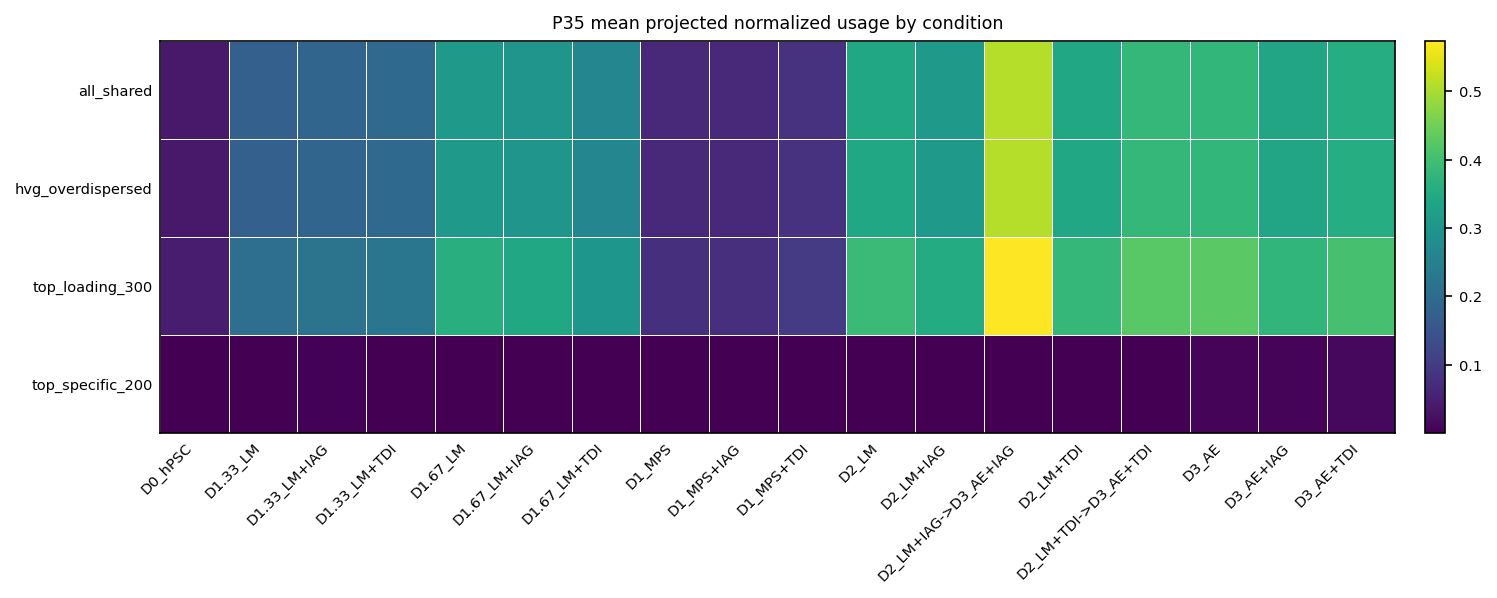

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

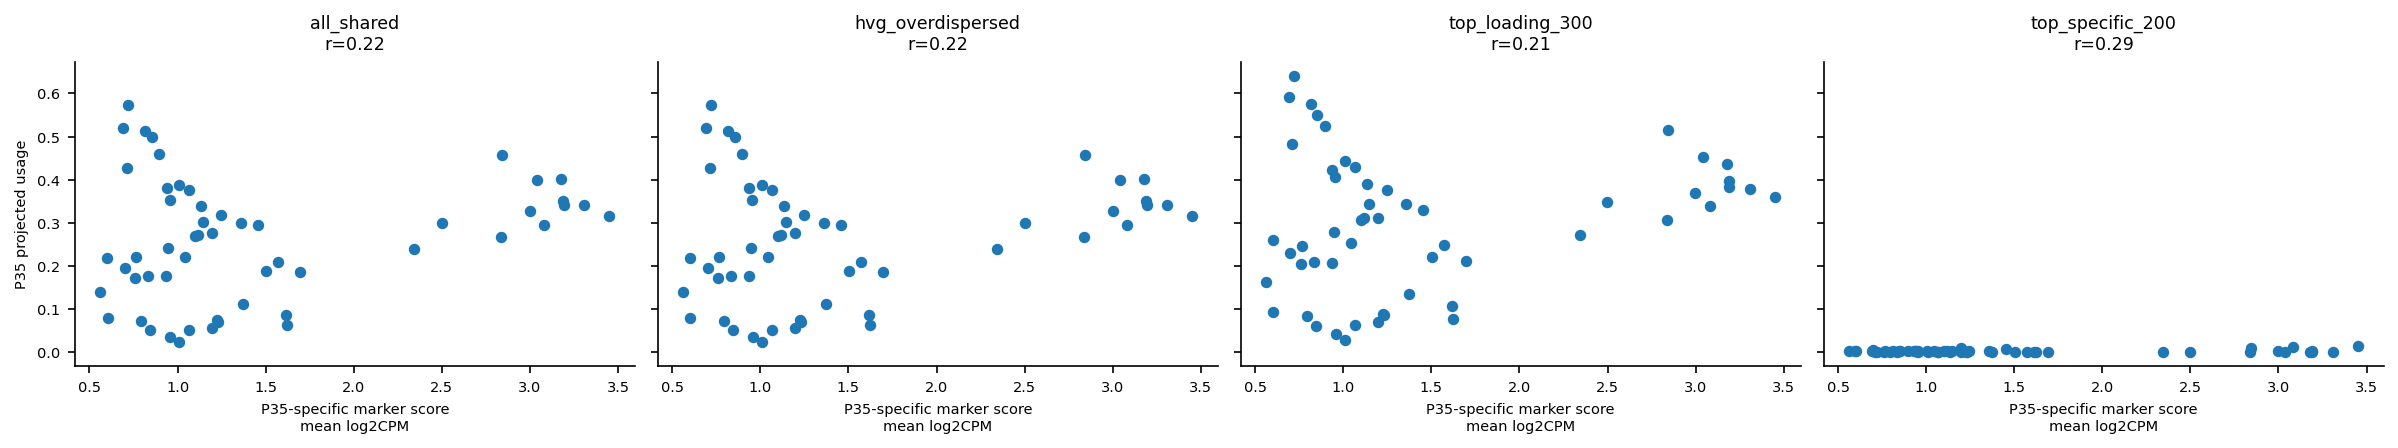

In [8]:
# P35 marker expression score from query counts.
if len(P35_MARKERS) > 0:
    X_p35, present_marker_genes = build_collapsed_query_matrix(X_counts, query_gene_ids, P35_MARKERS, total_counts)
    marker_expr = np.asarray(X_p35.mean(axis=1)).ravel()
    marker_expr_log = np.log2(marker_expr + 1)
else:
    present_marker_genes = []
    marker_expr_log = np.full(adata.n_obs, np.nan)

p35_records = []
program_idx = program_names.index(PROGRAM_OF_INTEREST)
for mode in projection_usages:
    for source_name, mat in [
        ("usage_norm", projection_usages[mode]),
        ("clr", projection_clr[mode]),
    ]:
        vals = mat[:, program_idx]
        tmp = pd.DataFrame({
            "condition": adata.obs["condition"].astype(str).to_numpy(),
            "sample_name": adata.obs["sample_name"].astype(str).to_numpy(),
            "qc_pass": adata.obs["qc_pass_condition_specific"].to_numpy(),
            "p35_value": vals,
            "p35_marker_log2meanCPM": marker_expr_log,
        })
        # Condition means among QC-passing cells.
        cond_mean = tmp[tmp["qc_pass"]].groupby("condition", observed=True)[["p35_value", "p35_marker_log2meanCPM"]].mean()
        sample_mean = tmp[tmp["qc_pass"]].groupby("sample_name", observed=True)[["p35_value", "p35_marker_log2meanCPM"]].mean()
        corr_cond = cond_mean.corr().loc["p35_value", "p35_marker_log2meanCPM"] if cond_mean.shape[0] > 2 else np.nan
        corr_sample = sample_mean.corr().loc["p35_value", "p35_marker_log2meanCPM"] if sample_mean.shape[0] > 2 else np.nan
        p35_records.append({
            "projection_mode": mode,
            "source": source_name,
            "p35_condition_mean_min": float(cond_mean["p35_value"].min()),
            "p35_condition_mean_max": float(cond_mean["p35_value"].max()),
            "p35_condition_mean_range": float(cond_mean["p35_value"].max() - cond_mean["p35_value"].min()),
            "p35_condition_mean_sd": float(cond_mean["p35_value"].std()),
            "p35_corr_with_marker_expr_by_condition": corr_cond,
            "p35_corr_with_marker_expr_by_sample": corr_sample,
            "n_p35_marker_genes_used": len(present_marker_genes),
        })

p35_diag = pd.DataFrame(p35_records).sort_values(["source", "p35_corr_with_marker_expr_by_sample"], ascending=[True, False])
p35_diag.to_csv(OUT_DIR / "P35_projection_diagnostic_metrics_by_gene_set.tsv", sep="\t", index=False)
display(p35_diag)

# Plot P35 condition means for each mode.
mode_condition_tables = []
for mode in projection_usages:
    vals = projection_usages[mode][:, program_idx]
    tmp = pd.DataFrame({
        "condition": adata.obs["condition"].astype(str).to_numpy(),
        "qc_pass": adata.obs["qc_pass_condition_specific"].to_numpy(),
        "value": vals,
    })
    cond = tmp[tmp["qc_pass"]].groupby("condition", observed=True)["value"].mean().rename(mode)
    mode_condition_tables.append(cond)
P35_condition_usage = pd.concat(mode_condition_tables, axis=1).T
P35_condition_usage.to_csv(OUT_DIR / "P35_mean_projected_usage_by_condition_across_gene_sets.tsv", sep="\t")
plot_heatmap(
    P35_condition_usage,
    title="P35 mean projected normalized usage by condition",
    out_prefix="P35_mean_usage_by_condition_across_gene_sets",
    center_zero=False,
    cmap="viridis",
)

# Scatter: P35 sample mean vs P35 marker expression sample mean.
fig, axes = plt.subplots(1, len(projection_usages), figsize=(4 * len(projection_usages), 3), sharey=True)
if len(projection_usages) == 1:
    axes = [axes]
for ax, mode in zip(axes, projection_usages):
    vals = projection_usages[mode][:, program_idx]
    tmp = pd.DataFrame({
        "sample_name": adata.obs["sample_name"].astype(str).to_numpy(),
        "qc_pass": adata.obs["qc_pass_condition_specific"].to_numpy(),
        "p35_usage": vals,
        "marker": marker_expr_log,
    })
    sm = tmp[tmp["qc_pass"]].groupby("sample_name", observed=True)[["p35_usage", "marker"]].mean()
    corr = sm.corr().loc["p35_usage", "marker"] if sm.shape[0] > 2 else np.nan
    ax.scatter(sm["marker"], sm["p35_usage"], s=20)
    ax.set_title(f"{mode}\nr={corr:.2f}")
    ax.set_xlabel("P35-specific marker score\nmean log2CPM")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("P35 projected usage")
fig.tight_layout()
for ext in ["svg", "pdf", "png"]:
    fig.savefig(FIG_DIR / f"P35_usage_vs_marker_score_by_sample.{ext}", bbox_inches="tight")
plt.show()
plt.close(fig)

## Diagnostics: matched CLR effects for key programs across projection modes

,projection_mode,contrast_name,treatment,treated_condition,control_condition,program,n_matched_pairs,mean_control_clr,mean_treated_clr,mean_diff_clr,sd_diff_clr,t_statistic,pvalue,n_positive_diffs,n_negative_diffs,padj_bh_within_mode_contrast
65,all_shared,D2_IAG,IAG,D2_LM+IAG,D2_LM,P15,3,4.274962,7.225441,2.950480,3.302757,1.547308,0.261860,2,1,0.478873
365,hvg_overdispersed,D2_IAG,IAG,D2_LM+IAG,D2_LM,P15,3,4.274962,7.225441,2.950480,3.302757,1.547308,0.261860,2,1,0.478873
665,top_loading_300,D2_IAG,IAG,D2_LM+IAG,D2_LM,P15,3,4.144684,7.015725,2.871041,3.260914,1.524968,0.266768,2,1,0.474914
965,top_specific_200,D2_IAG,IAG,D2_LM+IAG,D2_LM,P15,3,10.787770,13.103684,2.315914,0.121315,33.065045,0.000913,3,0,0.022835
15,all_shared,D2_TDI,TDI,D2_LM+TDI,D2_LM,P15,3,4.274962,0.356734,-3.918228,2.202960,-3.080660,0.091186,0,3,0.808091
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1085,top_specific_200,D3_IAG,IAG,D3_AE+IAG,D3_AE,P35,3,0.661710,0.090613,-0.571097,0.056053,-17.646881,0.003196,0,3,0.156028
135,all_shared,D3_TDI,TDI,D3_AE+TDI,D3_AE,P35,3,15.250503,14.423367,-0.827137,2.023800,-0.707898,0.552386,1,2,0.878304
435,hvg_overdispersed,D3_TDI,TDI,D3_AE+TDI,D3_AE,P35,3,15.250503,14.423367,-0.827137,2.023800,-0.707898,0.552386,1,2,0.878304
735,top_loading_300,D3_TDI,TDI,D3_AE+TDI,D3_AE,P35,3,15.519336,14.707118,-0.812218,1.998881,-0.703795,0.554464,1,2,0.841288


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

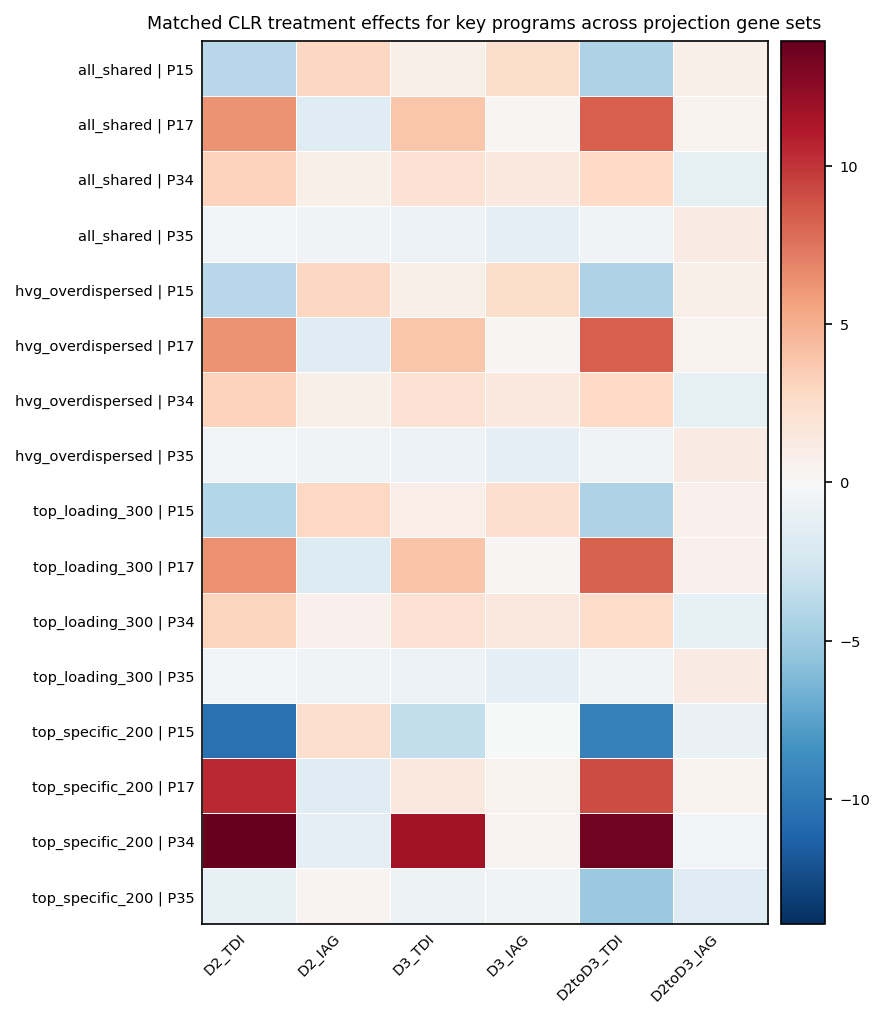

In [9]:
effect_tables = []
for mode in projection_clr:
    clr_df = pd.DataFrame(projection_clr[mode], index=adata.obs_names.astype(str), columns=program_names)
    clr_df["sample_name"] = adata.obs["sample_name"].astype(str).to_numpy()
    clr_df["qc_pass"] = adata.obs["qc_pass_condition_specific"].to_numpy()
    sample_clr_mean = clr_df[clr_df["qc_pass"]].groupby("sample_name", observed=True)[program_names].mean()
    sample_meta = (
        adata.obs[["sample_name", "condition", "replicate"]]
        .drop_duplicates("sample_name")
        .set_index("sample_name")
        .loc[sample_clr_mean.index]
    )
    effects = paired_clr_effects(sample_clr_mean, sample_meta, program_names, mode)
    effect_tables.append(effects)

all_effects = pd.concat(effect_tables, ignore_index=True)
all_effects.to_csv(OUT_DIR / "matched_CLR_effects_all_programs_across_projection_gene_sets.tsv", sep="\t", index=False)

key_effects = all_effects[all_effects["program"].isin(KEY_PROGRAMS)].copy()
key_effects.to_csv(OUT_DIR / "matched_CLR_effects_key_programs_across_projection_gene_sets.tsv", sep="\t", index=False)
display(key_effects.sort_values(["program", "contrast_name", "projection_mode"]))

# Heatmap for key programs/effects by mode.
key_effects["row"] = key_effects["projection_mode"] + " | " + key_effects["program"]
key_effects["col"] = key_effects["contrast_name"]
key_mat = key_effects.pivot(index="row", columns="col", values="mean_diff_clr")
key_mat = key_mat[[c["name"] for c in CONTRASTS if c["name"] in key_mat.columns]]
key_mat.to_csv(OUT_DIR / "key_program_CLR_effect_heatmap_matrix_across_gene_sets.tsv", sep="\t")
plot_heatmap(
    key_mat,
    title="Matched CLR treatment effects for key programs across projection gene sets",
    out_prefix="key_program_CLR_effects_across_projection_gene_sets",
    center_zero=True,
    cmap="RdBu_r",
)

## Interpretation helper table

In [10]:
# A simple summary: better modes should ideally show less broad P35 baseline and higher correlation with P35 marker expression,
# while preserving key P15/P17/P34 treatment effects.
summary = p35_diag.merge(projection_stats_df, on="projection_mode", how="left")
summary.to_csv(OUT_DIR / "projection_gene_set_comparison_summary.tsv", sep="\t", index=False)
print("Saved outputs to", OUT_DIR)
display(summary)

print("\nWhat to look for:")
print("1. P35 p35_condition_mean_sd/range: if lower, P35 is less condition-specific; if P35 is high everywhere, range may be small relative to mean.")
print("2. P35_corr_with_marker_expr_by_sample: higher is better if P35 usage tracks P35-specific marker genes.")
print("3. key_program_CLR_effects_across_projection_gene_sets: P15/P17/P34 conclusions should remain stable.")
print("4. If hvg_overdispersed or top_specific reduces broad P35 but preserves key effects, use it as a better projection mode.")

Saved outputs to /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/reprojection_gene_set_comparison


,projection_mode,source,p35_condition_mean_min,p35_condition_mean_max,p35_condition_mean_range,p35_condition_mean_sd,p35_corr_with_marker_expr_by_condition,p35_corr_with_marker_expr_by_sample,n_p35_marker_genes_used,n_genes,n_iter
0,top_loading_300,clr,9.070733,16.654522,7.583789,2.242190,0.264748,0.206164,25,3297,1000
1,all_shared,clr,8.718720,16.406996,7.688275,2.261395,0.262884,0.204671,25,17480,920
2,hvg_overdispersed,clr,8.718720,16.406996,7.688275,2.261395,0.262884,0.204671,25,17480,920
3,top_specific_200,clr,-4.706792,0.979022,5.685814,1.753387,-0.195083,-0.186214,25,7268,140
4,top_specific_200,usage_norm,0.000087,0.011716,0.011630,0.002800,0.268464,0.288559,25,7268,140
5,all_shared,usage_norm,0.036412,0.508500,0.472088,0.132583,0.277349,0.218064,25,17480,920
6,hvg_overdispersed,usage_norm,0.036412,0.508500,0.472088,0.132583,0.277349,0.218064,25,17480,920
7,top_loading_300,usage_norm,0.044514,0.573097,0.528583,0.147230,0.268167,0.209859,25,3297,1000



What to look for:
1. P35 p35_condition_mean_sd/range: if lower, P35 is less condition-specific; if P35 is high everywhere, range may be small relative to mean.
2. P35_corr_with_marker_expr_by_sample: higher is better if P35 usage tracks P35-specific marker genes.
3. key_program_CLR_effects_across_projection_gene_sets: P15/P17/P34 conclusions should remain stable.
4. If hvg_overdispersed or top_specific reduces broad P35 but preserves key effects, use it as a better projection mode.


Reading: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/reprojection_gene_set_comparison/matched_CLR_effects_all_programs_across_projection_gene_sets.tsv


,D2_TDI,D2_IAG,D3_TDI,D3_IAG,D2toD3_TDI,D2toD3_IAG
row_label,,,,,,
all_shared | P15,-3.918228,2.950480,0.809610,2.422269,-4.281097,0.864745
all_shared | P17,6.286915,-1.738138,3.906096,0.194969,8.302718,0.594220
all_shared | P34,3.164731,0.783024,2.115612,1.511349,2.767974,-1.221056
all_shared | P35,-0.501616,-0.620107,-0.827137,-1.338579,-0.652095,1.154775
all_shared | P2,-0.378441,-0.368888,-0.676170,0.011447,-1.663262,2.370678
hvg_overdispersed | P15,-3.918228,2.950480,0.809610,2.422269,-4.281097,0.864745
hvg_overdispersed | P17,6.286915,-1.738138,3.906096,0.194969,8.302718,0.594220
hvg_overdispersed | P34,3.164731,0.783024,2.115612,1.511349,2.767974,-1.221056
hvg_overdispersed | P35,-0.501616,-0.620107,-0.827137,-1.338579,-0.652095,1.154775


Saved source: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/reprojection_gene_set_comparison/figures/key_program_CLR_effects_across_projection_gene_sets_with_P2_source_long.tsv
Saved matrix: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/reprojection_gene_set_comparison/figures/key_program_CLR_effects_across_projection_gene_sets_with_P2_matrix.tsv
Saved q-values: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/reprojection_gene_set_comparison/figures/key_program_CLR_effects_across_projection_gene_sets_with_P2_qvalues.tsv


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

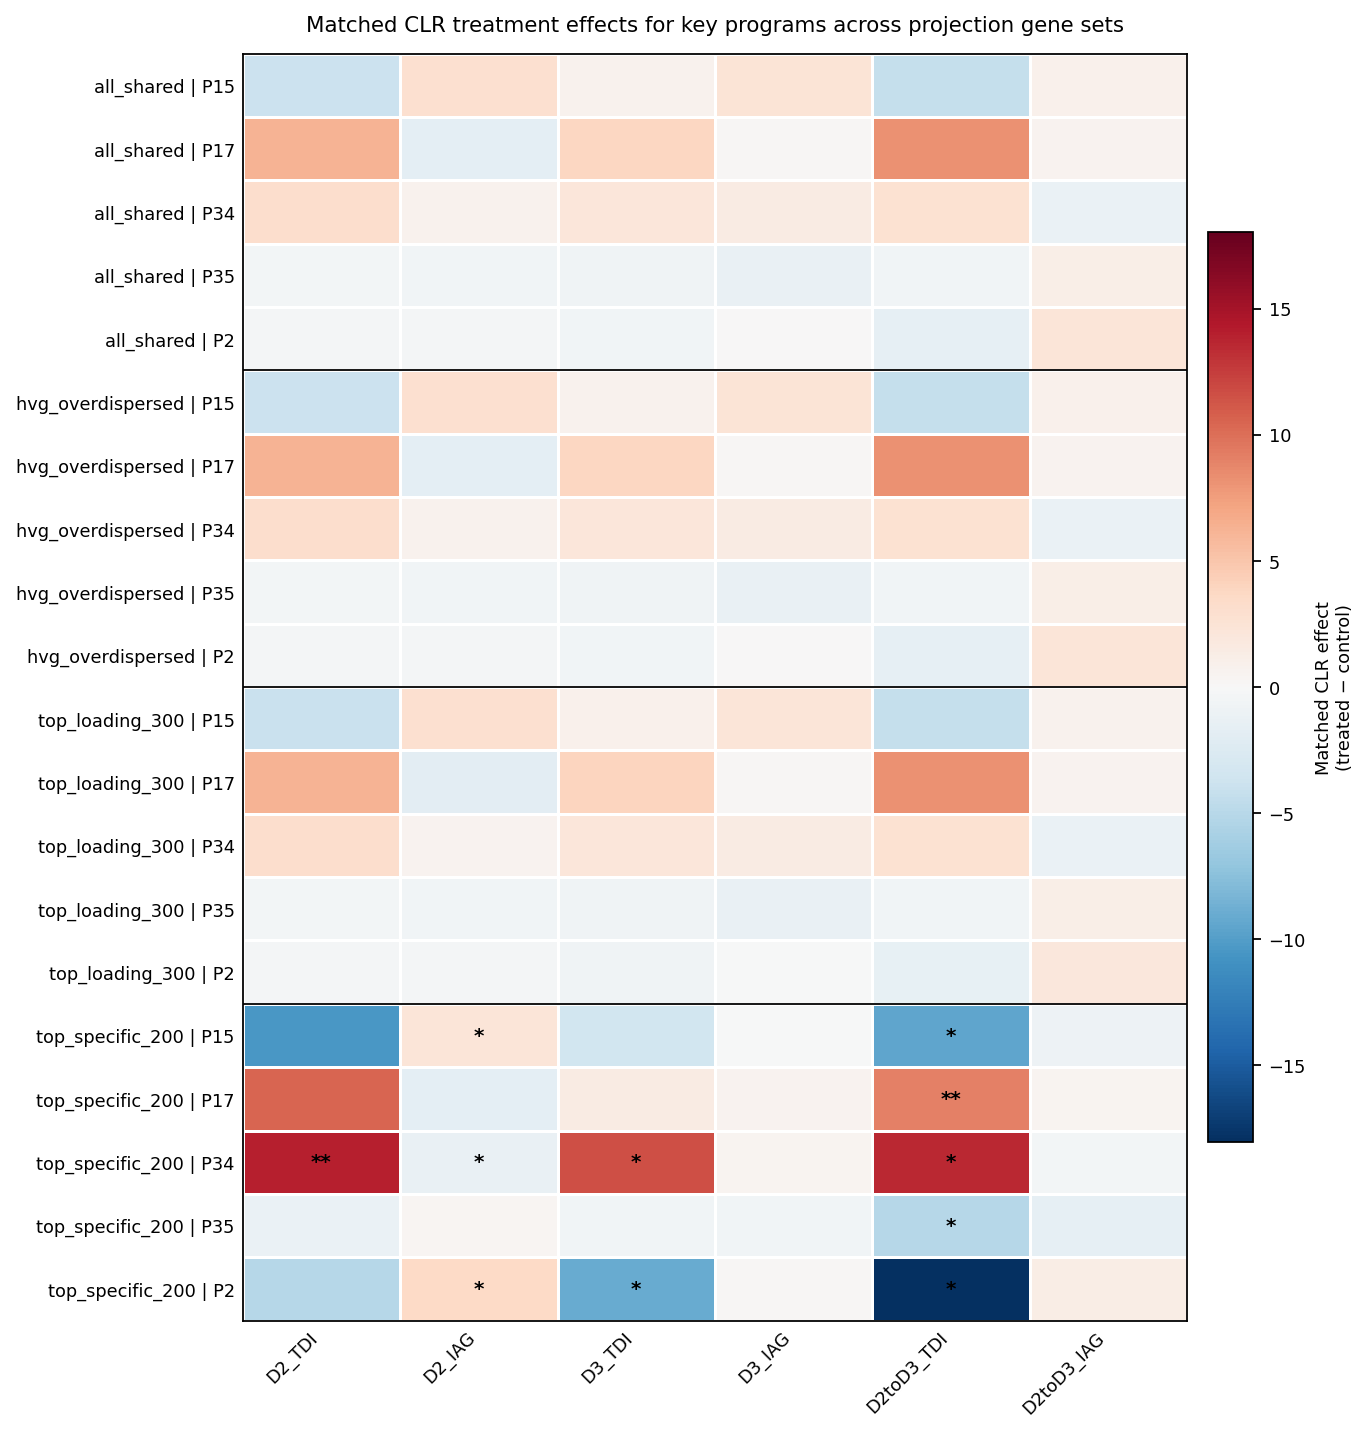

Saved figures to: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/reprojection_gene_set_comparison/figures
SVG: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/reprojection_gene_set_comparison/figures/key_program_CLR_effects_across_projection_gene_sets_with_P2.svg
PDF: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/reprojection_gene_set_comparison/figures/key_program_CLR_effects_across_projection_gene_sets_with_P2.pdf
PNG: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/reprojection_gene_set_comparison/figures/key_program_CLR_effects_across_projection_gene_sets_with_P2.png


In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 8,
    "figure.dpi": 160,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",  # Illustrator-editable text
})

# ============================================================
# Settings
# ============================================================

# Use the all-program table, not the key-program table.
RESULTS_PATH = Path(
    "/scratch/users/edtng/20260325_Hippo_timecourse/"
    "perturbseq_cNMF_projection/reprojection_gene_set_comparison/"
    "matched_CLR_effects_all_programs_across_projection_gene_sets.tsv"
)

# Fallback if running locally from uploaded files.
if not RESULTS_PATH.exists() and Path("/mnt/data/matched_CLR_effects_all_programs_across_projection_gene_sets.tsv").exists():
    RESULTS_PATH = Path("/mnt/data/matched_CLR_effects_all_programs_across_projection_gene_sets.tsv")

OUT_DIR = RESULTS_PATH.parent / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Keep the same modes shown in your current figure.
PROJECTION_MODES = [
    "all_shared",
    "hvg_overdispersed",
    "top_loading_300",
    "top_specific_200",
]

# Original programs plus P2.
# Edit order here if you want P2 somewhere else.
PROGRAMS = [
    "P15",
    "P17",
    "P34",
    "P35",
    "P2",
]

CONTRASTS = [
    "D2_TDI",
    "D2_IAG",
    "D3_TDI",
    "D3_IAG",
    "D2toD3_TDI",
    "D2toD3_IAG",
]

CONTRAST_LABELS = {
    "D2_TDI": "D2_TDI",
    "D2_IAG": "D2_IAG",
    "D3_TDI": "D3_TDI",
    "D3_IAG": "D3_IAG",
    "D2toD3_TDI": "D2toD3_TDI",
    "D2toD3_IAG": "D2toD3_IAG",
}

VALUE_COL = "mean_diff_clr"
PADJ_COL = "padj_bh_within_mode_contrast"

OUT_PREFIX = "key_program_CLR_effects_across_projection_gene_sets_with_P2"

print("Reading:", RESULTS_PATH)

# ============================================================
# Load and reshape
# ============================================================

df = pd.read_csv(RESULTS_PATH, sep="\t")

required = [
    "projection_mode",
    "contrast_name",
    "program",
    VALUE_COL,
    PADJ_COL,
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

sub = df[
    df["projection_mode"].isin(PROJECTION_MODES)
    & df["program"].isin(PROGRAMS)
    & df["contrast_name"].isin(CONTRASTS)
].copy()

# Check all expected rows exist.
expected = pd.MultiIndex.from_product(
    [PROJECTION_MODES, PROGRAMS, CONTRASTS],
    names=["projection_mode", "program", "contrast_name"],
)

observed = pd.MultiIndex.from_frame(
    sub[["projection_mode", "program", "contrast_name"]]
)

missing_rows = expected.difference(observed)

if len(missing_rows) > 0:
    print("WARNING: missing rows:")
    display(missing_rows.to_frame(index=False).head(50))

# Row labels as "mode | program"
sub["row_label"] = sub["projection_mode"] + " | " + sub["program"]

ROW_ORDER = [
    f"{mode} | {program}"
    for mode in PROJECTION_MODES
    for program in PROGRAMS
]

sub["row_label"] = pd.Categorical(
    sub["row_label"],
    categories=ROW_ORDER,
    ordered=True,
)

sub["contrast_name"] = pd.Categorical(
    sub["contrast_name"],
    categories=CONTRASTS,
    ordered=True,
)

effect_mat = (
    sub
    .pivot(index="row_label", columns="contrast_name", values=VALUE_COL)
    .reindex(index=ROW_ORDER, columns=CONTRASTS)
)

q_mat = (
    sub
    .pivot(index="row_label", columns="contrast_name", values=PADJ_COL)
    .reindex(index=ROW_ORDER, columns=CONTRASTS)
)

# Rename columns for display.
effect_mat.columns = [CONTRAST_LABELS.get(c, c) for c in effect_mat.columns]
q_mat.columns = effect_mat.columns

display(effect_mat)

# Save source table/matrix.
source_out = OUT_DIR / f"{OUT_PREFIX}_source_long.tsv"
matrix_out = OUT_DIR / f"{OUT_PREFIX}_matrix.tsv"
q_out = OUT_DIR / f"{OUT_PREFIX}_qvalues.tsv"

sub.to_csv(source_out, sep="\t", index=False)
effect_mat.to_csv(matrix_out, sep="\t")
q_mat.to_csv(q_out, sep="\t")

print("Saved source:", source_out)
print("Saved matrix:", matrix_out)
print("Saved q-values:", q_out)

# ============================================================
# Plot
# ============================================================

values = effect_mat.to_numpy(dtype=float)

vmax = np.nanmax(np.abs(values))
if not np.isfinite(vmax) or vmax == 0:
    vmax = 1

fig_w = 8.6
fig_h = max(7.2, 0.34 * effect_mat.shape[0] + 2.2)

fig, ax = plt.subplots(figsize=(fig_w, fig_h))

mesh = ax.pcolormesh(
    np.arange(effect_mat.shape[1] + 1),
    np.arange(effect_mat.shape[0] + 1),
    values,
    cmap="RdBu_r",
    vmin=-vmax,
    vmax=vmax,
    shading="flat",
    linewidth=0.6,
    edgecolors="white",
)

ax.set_xlim(0, effect_mat.shape[1])
ax.set_ylim(effect_mat.shape[0], 0)

ax.set_xticks(np.arange(effect_mat.shape[1]) + 0.5)
ax.set_yticks(np.arange(effect_mat.shape[0]) + 0.5)

ax.set_xticklabels(effect_mat.columns.tolist(), rotation=45, ha="right")
ax.set_yticklabels(effect_mat.index.tolist())

ax.set_title(
    "Matched CLR treatment effects for key programs across projection gene sets",
    pad=10,
)
ax.set_xlabel("")
ax.set_ylabel("")

# Add separators between projection modes.
for i in range(len(PROGRAMS), len(ROW_ORDER), len(PROGRAMS)):
    ax.axhline(i, color="black", linewidth=0.8)

# Add stars for adjusted p-values.
# * q < 0.05, ** q < 0.01, *** q < 0.001
for i, row in enumerate(effect_mat.index):
    for j, col in enumerate(effect_mat.columns):
        q = q_mat.loc[row, col]
        if pd.isna(q):
            continue

        if q < 0.001:
            star = "***"
        elif q < 0.01:
            star = "**"
        elif q < 0.05:
            star = "*"
        else:
            star = ""

        if star:
            ax.text(
                j + 0.5,
                i + 0.5,
                star,
                ha="center",
                va="center",
                fontsize=9,
                color="black",
                fontweight="bold",
            )

# Colorbar
cbar = fig.colorbar(mesh, ax=ax, pad=0.02, fraction=0.045)
cbar.set_label("Matched CLR effect\n(treated − control)")

# Make edges clean.
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

fig.tight_layout()

for ext in ["svg", "pdf", "png"]:
    fig.savefig(OUT_DIR / f"{OUT_PREFIX}.{ext}", bbox_inches="tight")

plt.show()
plt.close(fig)

print("Saved figures to:", OUT_DIR)
print("SVG:", OUT_DIR / f"{OUT_PREFIX}.svg")
print("PDF:", OUT_DIR / f"{OUT_PREFIX}.pdf")
print("PNG:", OUT_DIR / f"{OUT_PREFIX}.png")

#### Remake the projection adata using top 200 specific genes

In [12]:
# %% [markdown]
# # Make Hunter cell × cNMF program AnnData using top_specific_200 projection
#
# This creates a QC-filtered AnnData where:
#
# ```python
# adata.X = cell-level CLR(top_specific_200 projected usage) - matched-control replicate mean CLR
# ```
#
# It is analogous to the Hunter file made previously, but uses the `top_specific_200`
# gene set instead of all shared genes.

# %%
from __future__ import annotations

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
from scipy import sparse

warnings.filterwarnings("ignore")

# Optional only needed when reprojection output does not already exist.
try:
    from sklearn.decomposition import non_negative_factorization
except Exception:
    non_negative_factorization = None

# %% [markdown]
# ## Settings

# %%
BASE = Path("/scratch/users/edtng/20260325_Hippo_timecourse")
PROJ_DIR = BASE / "perturbseq_cNMF_projection"

# Original full projected AnnData, with RNA genes and obs metadata.
SOURCE_H5AD = PROJ_DIR / "Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad"

# Optional reprojection comparison output from previous notebook.
# If this file exists and contains obsm['X_cnmf_usage_top_specific_200'],
# this script will use it and skip the expensive reprojection step.
REPROJECTED_H5AD = (
    PROJ_DIR
    / "reprojection_gene_set_comparison"
    / "Hippo_timecourse_reprojected_cNMF_compare_gene_sets.cell_x_program.h5ad"
)

# Reference spectra and output directory.
SPECTRA_TPM = Path(
    "/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/"
    "030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50/"
    "030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50."
    "gene_spectra_tpm.k_50.dt_0_2.txt"
)

PROGRAM_META_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/data/program_activity_long_v4.csv"
)

OUT_DIR = PROJ_DIR / "hunter_cell_x_cnmf_clr_top_specific_200"
OUT_DIR.mkdir(parents=True, exist_ok=True)

OUT_H5AD = OUT_DIR / "Hippo_timecourse_cells_x_cNMF_top_specific_200_CLR_delta_matched_control.qc_filtered.h5ad"
OUT_SAMPLE_BASELINE = OUT_DIR / "matched_control_sample_mean_CLR_top_specific_200.tsv"
OUT_QC_SUMMARY = OUT_DIR / "condition_specific_QC_filter_summary.tsv"
OUT_CELL_SUMMARY = OUT_DIR / "cell_counts_by_sample_after_QC.tsv"
OUT_GENE_SET = OUT_DIR / "top_specific_200_genes_used_for_projection.txt"

# Score/projection settings.
MODE = "top_specific_200"
N_TOP_SPECIFIC = 200
SCORE_OBSM_KEY = f"X_cnmf_usage_{MODE}"
RAW_OBSM_KEY = f"X_cnmf_usage_raw_{MODE}"
CLR_OBSM_KEY = f"X_cnmf_clr_{MODE}"

# Query expression settings, used only if reprojection must be computed.
# For your dataset, QUERY_GENE_ID_SOURCE='column', QUERY_GENE_COLUMN='gene' is usually correct.
QUERY_GENE_ID_SOURCE = "column"  # 'var_names' or 'column'
QUERY_GENE_COLUMN = "gene"
COUNTS_SOURCE = "X"              # 'X' or 'layer:<name>'

# Fixed-H NMF settings, used only if reprojection must be computed.
SKLEARN_MAX_ITER = 1000
SKLEARN_TOL = 1e-5
RANDOM_STATE = 0

# CLR settings.
CLR_EPS = 1e-6
LOG_BASE = 2

# Save only QC-passed cells for Hunter.
SAVE_QC_FILTERED_ONLY = True

# %% [markdown]
# ## QC cutoffs

# %%
cond_pct_ribo_cutoffs = {
    'D0_hPSC': 2.4,
    'D1_MPS': 2.3,
    'D1_MPS+TDI': 2.5,
    'D1_MPS+IAG': 2.2,
    'D1.33_LM': 1.9,
    'D1.33_LM+TDI': 2.1,
    'D1.33_LM+IAG': 2.2,
    'D1.67_LM': 2.0,
    'D1.67_LM+TDI': 2.2,
    'D1.67_LM+IAG': 1.9,
    'D2_LM': 2.0,
    'D2_LM+TDI': 2.4,
    'D2_LM+IAG': 1.9,
    'D3_AE': 1.0,
    'D3_AE+TDI': 2.0,
    'D3_AE+IAG': 1.0,
    'D2_LM+TDI->D3_AE+TDI': 2.5,
    'D2_LM+IAG->D3_AE+IAG': 1.0,
}

cond_pct_mt_cutoffs = {
    'D0_hPSC': 5.5,
    'D1_MPS': 3.0,
    'D1_MPS+TDI': 3.0,
    'D1_MPS+IAG': 4,
    'D1.33_LM': 3.5,
    'D1.33_LM+TDI': 3.75,
    'D1.33_LM+IAG': 5,
    'D1.67_LM': 4.0,
    'D1.67_LM+TDI': 5.5,
    'D1.67_LM+IAG': 3.5,
    'D2_LM': 6.5,
    'D2_LM+TDI': 8,
    'D2_LM+IAG': 3.5,
    'D3_AE': 3.25,
    'D3_AE+TDI': 7.0,
    'D3_AE+IAG': 3.75,
    'D2_LM+TDI->D3_AE+TDI': 7,
    'D2_LM+IAG->D3_AE+IAG': 3.75,
}

assert set(cond_pct_ribo_cutoffs) == set(cond_pct_mt_cutoffs)

# %% [markdown]
# ## Helper functions

# %%
def parse_sample_name(sample_name: str):
    """Parse condition and replicate from sample_name, e.g. D2_LM+TDI_rep2."""
    sample_name = str(sample_name)
    m = re.match(r"^(.*)_rep(\d+)$", sample_name)
    if m is None:
        raise ValueError(f"Could not parse condition/replicate from sample_name={sample_name!r}")
    return m.group(1), int(m.group(2))


def infer_treatment(condition: str):
    condition = str(condition)
    if "IAG" in condition:
        return "IAG"
    if "TDI" in condition:
        return "TDI"
    return "control"


def strip_treatment(stage: str):
    return str(stage).replace("+TDI", "").replace("+IAG", "")


def matching_control_condition(condition: str):
    """Match treatment condition to its endpoint-matched control condition."""
    condition = str(condition)
    treatment = infer_treatment(condition)
    if treatment == "control":
        return condition
    if "->" in condition:
        endpoint = condition.split("->")[-1]
        return strip_treatment(endpoint)
    return strip_treatment(condition)


def program_num(program: str):
    m = re.fullmatch(r"P(\d+)", str(program))
    if m is None:
        raise ValueError(f"Invalid program name: {program!r}")
    return int(m.group(1))


def clr_transform_usage(usage, eps=1e-6, log_base=2):
    """CLR transform a cell x program compositional usage matrix."""
    usage = np.asarray(usage, dtype=np.float64)
    row_sums = usage.sum(axis=1, keepdims=True)
    if np.any(row_sums <= 0):
        n_zero = int((row_sums.ravel() <= 0).sum())
        raise ValueError(f"{n_zero} cells have zero total program usage.")
    usage = usage / row_sums
    usage = np.maximum(usage, eps)
    usage = usage / usage.sum(axis=1, keepdims=True)
    if log_base == 2:
        log_usage = np.log2(usage)
    elif log_base == "natural":
        log_usage = np.log(usage)
    else:
        raise ValueError("log_base must be 2 or 'natural'")
    clr = log_usage - log_usage.mean(axis=1, keepdims=True)
    return clr.astype(np.float32)


def load_program_labels(programs):
    labels = {p: p for p in programs}
    if not PROGRAM_META_PATH.exists():
        return labels
    meta = pd.read_csv(PROGRAM_META_PATH).drop_duplicates("program_name")
    if "program_label" not in meta.columns:
        return labels
    for _, row in meta.iterrows():
        if pd.isna(row["program_name"]):
            continue
        p = f"P{int(float(row['program_name']))}"
        if p in labels and pd.notna(row["program_label"]):
            labels[p] = str(row["program_label"])
    return labels


def read_reference_spectra():
    W = pd.read_csv(SPECTRA_TPM, sep="\t", index_col=0)
    W.index = W.index.astype(str)
    W.columns = W.columns.astype(str)
    W = W.apply(pd.to_numeric, errors="coerce").fillna(0.0)
    W[W < 0] = 0.0
    try:
        row_ids = [int(float(x)) for x in W.index]
        if row_ids == list(range(1, W.shape[0] + 1)):
            W.index = [f"P{i}" for i in range(W.shape[0])]
        elif row_ids == list(range(W.shape[0])):
            W.index = [f"P{i}" for i in row_ids]
    except Exception:
        pass
    W = W.loc[sorted(W.index, key=program_num)]
    return W


def make_top_specific_gene_set(W_ref, n_top=200):
    gene_total = W_ref.sum(axis=0).replace(0, np.nan)
    specificity = W_ref.div(gene_total, axis=1).fillna(0.0)
    genes = []
    for p in W_ref.index:
        tmp = pd.DataFrame({
            "gene": W_ref.columns.astype(str),
            "specificity": specificity.loc[p].to_numpy(),
            "weight": W_ref.loc[p].to_numpy(),
        }).sort_values(["specificity", "weight"], ascending=False)
        genes.extend(tmp.head(n_top)["gene"].tolist())
    genes = pd.Index(genes).drop_duplicates().astype(str).tolist()
    return genes


def get_query_gene_ids(adata):
    if QUERY_GENE_ID_SOURCE == "var_names":
        return pd.Index(adata.var_names.astype(str))
    if QUERY_GENE_ID_SOURCE == "column":
        if QUERY_GENE_COLUMN not in adata.var.columns:
            raise KeyError(f"{QUERY_GENE_COLUMN!r} not in adata.var")
        return pd.Index(adata.var[QUERY_GENE_COLUMN].astype(str).to_numpy())
    raise ValueError("QUERY_GENE_ID_SOURCE must be 'var_names' or 'column'")


def get_counts_matrix(adata):
    if COUNTS_SOURCE == "X":
        X = adata.X
    elif COUNTS_SOURCE.startswith("layer:"):
        layer = COUNTS_SOURCE.split(":", 1)[1]
        if layer not in adata.layers:
            raise KeyError(f"Layer {layer!r} not found")
        X = adata.layers[layer]
    else:
        raise ValueError("COUNTS_SOURCE must be 'X' or 'layer:<name>'")
    if not sparse.issparse(X):
        X = sparse.csr_matrix(X)
    else:
        X = X.tocsr()
    return X


def build_collapsed_query_matrix(adata, selected_genes):
    """Return CPM matrix cells x selected_genes, collapsed by query gene id."""
    query_gene_ids = get_query_gene_ids(adata)
    selected_genes = pd.Index(selected_genes).astype(str)

    gene_to_positions = {}
    for i, g in enumerate(query_gene_ids):
        if g in selected_genes:
            gene_to_positions.setdefault(str(g), []).append(i)

    present_genes = [g for g in selected_genes if str(g) in gene_to_positions]
    if len(present_genes) == 0:
        raise ValueError("No selected genes are present in query adata.")

    all_positions = sorted({pos for g in present_genes for pos in gene_to_positions[g]})
    pos_to_subcol = {pos: j for j, pos in enumerate(all_positions)}

    print(f"  Reading query expression for {len(present_genes):,} genes using {len(all_positions):,} query columns")
    X_all = get_counts_matrix(adata)
    X_sub = X_all[:, all_positions]

    # Collapse duplicated query symbols to one column per selected gene.
    rows = []
    cols = []
    data = []
    for out_j, gene in enumerate(present_genes):
        for pos in gene_to_positions[gene]:
            rows.append(pos_to_subcol[pos])
            cols.append(out_j)
            data.append(1.0)
    C = sparse.csr_matrix((data, (rows, cols)), shape=(len(all_positions), len(present_genes)), dtype=np.float32)
    X_counts = X_sub @ C
    X_counts = X_counts.tocsr().astype(np.float32)

    if "total_counts" in adata.obs.columns:
        total_counts = pd.to_numeric(adata.obs["total_counts"], errors="coerce").to_numpy(dtype=np.float32)
    else:
        total_counts = np.asarray(X_all.sum(axis=1)).ravel().astype(np.float32)
    total_counts = np.maximum(total_counts, 1.0)
    X_cpm = sparse.diags(1e6 / total_counts).dot(X_counts).tocsr().astype(np.float32)
    return X_cpm, present_genes


def project_fixed_spectra(X_cpm, H_program_by_gene, mode_name=MODE):
    if non_negative_factorization is None:
        raise ImportError("sklearn is needed to recompute projection but is not installed/importable")
    target_dtype = np.float32
    X_input = X_cpm.astype(target_dtype) if sparse.issparse(X_cpm) else np.asarray(X_cpm, dtype=target_dtype, order="C")
    H = np.asarray(H_program_by_gene, dtype=target_dtype, order="C")
    H[H < 0] = 0.0
    H_row_sums = H.sum(axis=1, keepdims=True)
    H = np.divide(H, np.maximum(H_row_sums, 1e-12), out=np.zeros_like(H), where=H_row_sums > 0).astype(target_dtype)
    print(f"  Projecting {mode_name}: X={X_input.shape} dtype={X_input.dtype}, H={H.shape} dtype={H.dtype}")
    W_usage, _, n_iter = non_negative_factorization(
        X_input,
        H=H,
        n_components=H.shape[0],
        update_H=False,
        init="custom",
        solver="mu",
        beta_loss="frobenius",
        max_iter=SKLEARN_MAX_ITER,
        tol=SKLEARN_TOL,
        random_state=RANDOM_STATE,
        verbose=0,
    )
    W_usage = np.asarray(W_usage, dtype=np.float32)
    row_sums = W_usage.sum(axis=1, keepdims=True)
    W_norm = np.divide(W_usage, row_sums, out=np.zeros_like(W_usage), where=row_sums > 0).astype(np.float32)
    print(f"  Done {mode_name}: n_iter={n_iter}; raw row sum range={row_sums.min():.4g}..{row_sums.max():.4g}")
    return W_usage, W_norm, int(n_iter)

# %% [markdown]
# ## Load data and get top_specific_200 usage

# %%
print("SOURCE_H5AD:", SOURCE_H5AD)
print("REPROJECTED_H5AD:", REPROJECTED_H5AD, REPROJECTED_H5AD.exists())
print("OUT_H5AD:", OUT_H5AD)

if REPROJECTED_H5AD.exists():
    print("Loading existing reprojection output")
    adata_src = sc.read_h5ad(REPROJECTED_H5AD)
    if SCORE_OBSM_KEY not in adata_src.obsm:
        raise KeyError(f"{SCORE_OBSM_KEY!r} not found in {REPROJECTED_H5AD}. obsm keys: {list(adata_src.obsm.keys())}")
    usage_norm = np.asarray(adata_src.obsm[SCORE_OBSM_KEY], dtype=np.float32)
    usage_raw = np.asarray(adata_src.obsm[RAW_OBSM_KEY], dtype=np.float32) if RAW_OBSM_KEY in adata_src.obsm else None
    if CLR_OBSM_KEY in adata_src.obsm:
        clr = np.asarray(adata_src.obsm[CLR_OBSM_KEY], dtype=np.float32)
    else:
        clr = clr_transform_usage(usage_norm, eps=CLR_EPS, log_base=LOG_BASE)
    obs = adata_src.obs.copy()
    program_names = [f"P{i}" for i in range(usage_norm.shape[1])]
    genes_used = None
else:
    print("Existing reprojection output not found; recomputing top_specific_200 projection")
    adata_src = sc.read_h5ad(SOURCE_H5AD)
    obs = adata_src.obs.copy()
    W_ref = read_reference_spectra()
    program_names = W_ref.index.astype(str).tolist()
    genes_all = make_top_specific_gene_set(W_ref, n_top=N_TOP_SPECIFIC)
    query_gene_ids = get_query_gene_ids(adata_src)
    genes_used = [g for g in genes_all if g in set(query_gene_ids.astype(str))]
    pd.Series(genes_used, name="gene").to_csv(OUT_GENE_SET, index=False, header=False)
    print(f"top_specific_200 genes in query: {len(genes_used):,}")
    X_cpm, present_genes = build_collapsed_query_matrix(adata_src, genes_used)
    H = W_ref.loc[program_names, present_genes].to_numpy()
    usage_raw, usage_norm, n_iter = project_fixed_spectra(X_cpm, H, MODE)
    clr = clr_transform_usage(usage_norm, eps=CLR_EPS, log_base=LOG_BASE)

print("usage_norm shape:", usage_norm.shape)
print("clr shape:", clr.shape)
print("obs shape:", obs.shape)

# %% [markdown]
# ## Parse metadata, apply condition-specific QC, and build matched control baselines

# %%
# Parse condition/replicate from sample_name if needed.
if "condition" not in obs.columns or "replicate" not in obs.columns:
    parsed = obs["sample_name"].astype(str).map(parse_sample_name)
    obs["condition"] = [x[0] for x in parsed]
    obs["replicate"] = [x[1] for x in parsed]

obs["condition"] = obs["condition"].astype(str)
obs["replicate"] = pd.to_numeric(obs["replicate"], errors="coerce").astype(int)
obs["treatment"] = obs["condition"].map(infer_treatment)
obs["matching_control_condition"] = obs["condition"].map(matching_control_condition)
obs["matching_control_sample"] = obs.apply(
    lambda r: f"{r['matching_control_condition']}_rep{int(r['replicate'])}",
    axis=1,
)

# QC-pass mask based on condition-specific thresholds.
for col in ["pct_counts_mt", "pct_counts_ribo"]:
    if col not in obs.columns:
        raise KeyError(f"{col!r} missing from obs")
    obs[col] = pd.to_numeric(obs[col], errors="coerce")

missing_cutoffs = sorted(set(obs["condition"]) - set(cond_pct_mt_cutoffs))
if missing_cutoffs:
    raise ValueError(f"Missing QC cutoffs for conditions: {missing_cutoffs}")

qc_pass = np.ones(obs.shape[0], dtype=bool)
qc_records = []
condition_values = obs["condition"].to_numpy()
mt = obs["pct_counts_mt"].to_numpy()
ribo = obs["pct_counts_ribo"].to_numpy()

for condition in sorted(obs["condition"].unique()):
    cond_mask = condition_values == condition
    fail_mt = cond_mask & (mt >= cond_pct_mt_cutoffs[condition])
    fail_ribo = cond_mask & (ribo <= cond_pct_ribo_cutoffs[condition])
    fail_any = fail_mt | fail_ribo
    qc_pass &= ~fail_any
    n_before = int(cond_mask.sum())
    n_removed = int(fail_any.sum())
    qc_records.append({
        "condition": condition,
        "n_before": n_before,
        "n_fail_mt": int(fail_mt.sum()),
        "n_fail_low_ribo": int(fail_ribo.sum()),
        "n_removed": n_removed,
        "n_after": n_before - n_removed,
        "fraction_removed": n_removed / n_before if n_before else np.nan,
        "mt_cutoff": cond_pct_mt_cutoffs[condition],
        "ribo_cutoff": cond_pct_ribo_cutoffs[condition],
    })

obs["qc_pass_condition_specific"] = qc_pass
qc_summary = pd.DataFrame(qc_records)
qc_summary.to_csv(OUT_QC_SUMMARY, sep="\t", index=False)
display(qc_summary)

# Sample-level matched control mean CLR, computed only from QC-passing control cells.
sample_names = obs["sample_name"].astype(str).to_numpy()
unique_control_samples = sorted(obs.loc[obs["treatment"] == "control", "sample_name"].astype(str).unique())
control_sample_means = {}

for control_sample in unique_control_samples:
    mask = qc_pass & (sample_names == control_sample)
    if mask.sum() == 0:
        print(f"WARNING: no QC-passing cells for control sample {control_sample}")
        continue
    control_sample_means[control_sample] = clr[mask].mean(axis=0)

baseline_df = pd.DataFrame(control_sample_means, index=program_names).T
baseline_df.index.name = "control_sample"
baseline_df.to_csv(OUT_SAMPLE_BASELINE, sep="\t")

# Cell-level delta = CLR(cell) - matched control replicate mean CLR.
delta = np.empty_like(clr, dtype=np.float32)
missing_baseline_cells = np.zeros(obs.shape[0], dtype=bool)
matching_samples = obs["matching_control_sample"].astype(str).to_numpy()

for control_sample, indices in pd.Series(np.arange(obs.shape[0])).groupby(matching_samples).groups.items():
    idx = np.asarray(list(indices), dtype=int)
    if control_sample not in control_sample_means:
        missing_baseline_cells[idx] = True
        delta[idx, :] = np.nan
    else:
        delta[idx, :] = clr[idx, :] - control_sample_means[control_sample]

obs["has_matching_control_baseline"] = ~missing_baseline_cells
obs["projection_gene_set"] = MODE
obs["clr_eps"] = CLR_EPS
obs["clr_log_base"] = str(LOG_BASE)

if missing_baseline_cells.any():
    print("WARNING: cells without matching control baseline:", int(missing_baseline_cells.sum()))

keep = qc_pass & (~missing_baseline_cells)
print(f"QC-passing cells with baselines: {keep.sum():,} / {len(keep):,}")

# %% [markdown]
# ## Save Hunter QC-filtered AnnData

# %%
program_labels = load_program_labels(program_names)
var = pd.DataFrame(index=pd.Index(program_names, name="program"))
var["program"] = program_names
var["program_number"] = [program_num(p) for p in program_names]
var["program_label"] = [program_labels[p] for p in program_names]
var["projection_gene_set"] = MODE
var["n_top_specific_per_program"] = N_TOP_SPECIFIC

obs_out = obs.loc[keep].copy()
# Make categorical/string columns safe for writing.
for col in obs_out.columns:
    if obs_out[col].dtype == object:
        obs_out[col] = obs_out[col].astype(str)

adata_hunter = ad.AnnData(
    X=delta[keep, :].astype(np.float32),
    obs=obs_out,
    var=var,
)

adata_hunter.layers[f"projected_usage_normalized_{MODE}"] = usage_norm[keep, :].astype(np.float32)
if usage_raw is not None:
    adata_hunter.layers[f"projected_usage_raw_{MODE}"] = usage_raw[keep, :].astype(np.float32)
adata_hunter.layers[f"clr_{MODE}"] = clr[keep, :].astype(np.float32)
adata_hunter.layers[f"clr_delta_vs_control_replicate_mean_{MODE}"] = delta[keep, :].astype(np.float32)

adata_hunter.uns["description"] = (
    "QC-filtered Hippo time-course cells x cNMF programs. "
    "X is log2 CLR(top_specific_200 projected usage) minus matched-control replicate mean CLR."
)
adata_hunter.uns["projection_gene_set"] = MODE
adata_hunter.uns["n_top_specific_per_program"] = N_TOP_SPECIFIC
adata_hunter.uns["clr_eps"] = CLR_EPS
adata_hunter.uns["clr_log_base"] = LOG_BASE
adata_hunter.uns["matching_control_logic"] = (
    "Control conditions are centered to their own replicate mean. "
    "TDI/IAG conditions are centered to the same-stage or endpoint-matched control replicate. "
    "D2_LM+TDI/IAG->D3_AE+TDI/IAG are centered to D3_AE replicate-matched controls."
)
adata_hunter.uns["qc_cutoffs_pct_mt"] = cond_pct_mt_cutoffs
adata_hunter.uns["qc_cutoffs_pct_ribo"] = cond_pct_ribo_cutoffs

if genes_used is not None:
    adata_hunter.uns["genes_used_for_projection"] = genes_used

# Validation: controls should have mean ~0 by sample.
X_delta = np.asarray(adata_hunter.X)
check = pd.DataFrame(X_delta, index=adata_hunter.obs_names, columns=program_names)
check["sample_name"] = adata_hunter.obs["sample_name"].astype(str).to_numpy()
check["treatment"] = adata_hunter.obs["treatment"].astype(str).to_numpy()
control_means = check.query("treatment == 'control'").groupby("sample_name")[program_names].mean()
centering_qc = pd.DataFrame({
    "max_abs_program_mean": control_means.abs().max(axis=1),
    "mean_abs_program_mean": control_means.abs().mean(axis=1),
})
centering_qc.to_csv(OUT_DIR / "control_sample_centering_QC_top_specific_200.tsv", sep="\t")
print("Control centering QC; should be near zero:")
display(centering_qc.sort_values("max_abs_program_mean", ascending=False))

cell_counts = (
    adata_hunter.obs.groupby(["condition", "sample_name"], observed=True)
    .size()
    .rename("n_qc_passing_cells")
    .reset_index()
)
cell_counts.to_csv(OUT_CELL_SUMMARY, sep="\t", index=False)

data_hunter_path = OUT_H5AD
adata_hunter.write_h5ad(data_hunter_path, compression="gzip")
print("Wrote:", data_hunter_path)
print(adata_hunter)



SOURCE_H5AD: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad
REPROJECTED_H5AD: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/reprojection_gene_set_comparison/Hippo_timecourse_reprojected_cNMF_compare_gene_sets.cell_x_program.h5ad True
OUT_H5AD: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/hunter_cell_x_cnmf_clr_top_specific_200/Hippo_timecourse_cells_x_cNMF_top_specific_200_CLR_delta_matched_control.qc_filtered.h5ad
Loading existing reprojection output
usage_norm shape: (212891, 50)
clr shape: (212891, 50)
obs shape: (212891, 69)


,condition,n_before,n_fail_mt,n_fail_low_ribo,n_removed,n_after,fraction_removed,mt_cutoff,ribo_cutoff
0,D0_hPSC,16770,4229,7841,7878,8892,0.469767,5.50,2.4
1,D1.33_LM,12548,6230,7371,7515,5033,0.598900,3.50,1.9
2,D1.33_LM+IAG,10934,4185,6219,6284,4650,0.574721,5.00,2.2
3,D1.33_LM+TDI,10245,4370,5366,5446,4799,0.531576,3.75,2.1
4,D1.67_LM,5335,2864,3131,3147,2188,0.589878,4.00,2.0
5,D1.67_LM+IAG,19448,8287,8964,9329,10119,0.479689,3.50,1.9
6,D1.67_LM+TDI,6459,1976,3002,3036,3423,0.470042,5.50,2.2
7,D1_MPS,7584,2876,2949,3014,4570,0.397416,3.00,2.3
8,D1_MPS+IAG,13131,6522,6728,6821,6310,0.519458,4.00,2.2
9,D1_MPS+TDI,10080,6811,5558,6999,3081,0.694345,3.00,2.5


QC-passing cells with baselines: 99,416 / 212,891
Control centering QC; should be near zero:


,max_abs_program_mean,mean_abs_program_mean
sample_name,,
D0_hPSC_rep2,0.000018,2.542070e-06
D0_hPSC_rep3,0.000017,2.394691e-06
D2_LM_rep3,0.000013,3.812912e-06
D1_MPS_rep1,0.000013,2.279848e-06
D2_LM_rep2,0.000012,1.727993e-06
D0_hPSC_rep1,0.000011,2.634991e-06
D3_AE_rep2,0.000010,1.661222e-06
D1.33_LM_rep1,0.000010,3.013320e-06
D2_LM_rep1,0.000009,2.220663e-06


Wrote: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/hunter_cell_x_cnmf_clr_top_specific_200/Hippo_timecourse_cells_x_cNMF_top_specific_200_CLR_delta_matched_control.qc_filtered.h5ad
AnnData object with n_obs × n_vars = 99416 × 50
    obs: 'guides_per_cell', 'guide_umi_counts', 'pct_counts_ribo', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'pool', 'sample_id', 'round1', 'well', 'biological_sample', 'plate', 'sublibID', 'sample_name', 'perturbseq_cNMF_P0_usage', 'perturbseq_cNMF_P1_usage', 'perturbseq_cNMF_P2_usage', 'perturbseq_cNMF_P3_usage', 'perturbseq_cNMF_P4_usage', 'perturbseq_cNMF_P5_usage', 'perturbseq_cNMF_P6_usage', 'perturbseq_cNMF_P7_usage', 'perturbseq_cNMF_P8_usage', 'perturbseq_cNMF_P9_usage', 'perturbseq_cNMF_P10_usage', 'perturbseq_cNMF_P11_usage', 'perturbseq_cNMF_P12_usage', 'perturbseq_cNMF_P13_usage', 'perturbseq_cNMF_P14_usage', 'perturbseq_cNMF_P15_usage', 'perturbseq_cNMF_P16_usage', 'perturbseq_cNMF_P17_u